# Asignación 3 — Model Selection, Ablación, Tuning y Evaluación Final (SSBM)

Este notebook implementa de forma integral las **6 prioridades experimentales** del dictamen del PR #2 sobre el dataset ampliado (`data/processed_dev.parquet`) y realiza una evaluación final **única** sobre el conjunto de Test y sobre un **nuevo conjunto *holdout* completamente intacto** (`data/processed_holdout.parquet`, particiones `00fd` y `00fe`).

Principios metodológicos aplicados:
- **Principio DRY:** Toda la ingeniería de características y construcción de pipelines se importa desde `src/features/transformers.py` (`MeleeFeatureEngineer`, `build_model_pipeline`) y `src/extract_data.py` (`canonicalize_match_ids`).
- **Cero fuga de información (Anti-Leakage):** El *split* agrupado por `match_id` ocurre tras canonicalizar partidas fragmentadas (`0000_m16`/`0000_m25`), todos los transformadores estadísticos se ajustan dentro de cada *fold* de CV, el umbral se optimiza exclusivamente sobre probabilidades *out-of-fold* (OOF), y Test/Holdout se evalúan **una sola vez** al final.

In [1]:
from __future__ import annotations

import json
import platform
import sys
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GroupKFold,
    GroupShuffleSplit,
    StratifiedGroupKFold,
    cross_val_predict,
    cross_validate,
)

warnings.filterwarnings("ignore", category=FutureWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)

assert tuple(int(p) for p in sklearn.__version__.split(".")[:2]) >= (1, 6), (
    f"Se requiere scikit-learn >= 1.6; instalado: {sklearn.__version__}"
)

REPO_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.extract_data import canonicalize_match_ids
from src.features.transformers import EPSILON, MeleeFeatureEngineer, build_model_pipeline

RANDOM_STATE = 42
TEST_SIZE = 0.20
TARGET = "outcome"
ID_GROUP = "match_id"
ID_FRAME = "row_id"
EARLY_END = 5000
MID_END = 12000

DEV_DATA_PATH = REPO_ROOT / "data" / "processed_dev.parquet"
HOLDOUT_DATA_PATH = REPO_ROOT / "data" / "processed_holdout.parquet"
ARTIFACTS_DIR = REPO_ROOT / "artifacts"
MODELS_DIR = REPO_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

assert DEV_DATA_PATH.exists(), f"No se encontró dataset dev: {DEV_DATA_PATH}"
assert HOLDOUT_DATA_PATH.exists(), f"No se encontró dataset holdout: {HOLDOUT_DATA_PATH}"

print(f"Python       : {platform.python_version()}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"Optuna       : {optuna.__version__}")
print(f"Dev dataset  : {DEV_DATA_PATH}")
print(f"Holdout path : {HOLDOUT_DATA_PATH} (reservado hasta Evaluación Final)")

/mnt/Qui/@home/spinangoalamo/codes/Machine Learning/super_smash_bros_melee_victory_predictor/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python       : 3.14.8
scikit-learn : 1.9.0
Optuna       : 5.0.0
Dev dataset  : /mnt/Qui/@home/spinangoalamo/codes/Machine Learning/super_smash_bros_melee_victory_predictor/data/processed_dev.parquet
Holdout path : /mnt/Qui/@home/spinangoalamo/codes/Machine Learning/super_smash_bros_melee_victory_predictor/data/processed_holdout.parquet (reservado hasta Evaluación Final)


## Sección 1 — Carga, Canonicalización Previa, Split Agrupado y Protocolo de CV

Cargamos `data/processed_dev.parquet` (6 particiones: `0000`–`0005`), verificamos la canonicalización previa de `match_id`, aplicamos la depuración fija de frames sin señal (`frame < 0` o `stock == 0`) y reproducimos el `GroupShuffleSplit(test_size=0.20, random_state=42)`. Asimismo comparamos `GroupKFold(5)` frente a `StratifiedGroupKFold(5)` para seleccionar el protocolo de validación cruzada más balanceado.

In [2]:
df_raw = pd.read_parquet(DEV_DATA_PATH)
df = canonicalize_match_ids(df_raw)
del df_raw

# Misma depuración determinista que Fase 2
df = df.loc[
    ~((df["frame"] < 0) | (df["p1_stock"] == 0) | (df["p2_stock"] == 0))
].reset_index(drop=True)

assert "0000_m25" not in set(df[ID_GROUP]), "0000_m25 debe estar unificado en 0000_m16 antes del split."

splitter = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(df, df[TARGET], groups=df[ID_GROUP]))

X_train = df.iloc[train_idx].drop(columns=[TARGET]).reset_index(drop=True)
X_test = df.iloc[test_idx].drop(columns=[TARGET]).reset_index(drop=True)
# Codificación binaria explícita: 1 = P1 gana, 0 = P2 gana
y_train = (df[TARGET].iloc[train_idx] == 1).astype(int).reset_index(drop=True)
y_test = (df[TARGET].iloc[test_idx] == 1).astype(int).reset_index(drop=True)

groups_train = X_train[ID_GROUP].to_numpy()
groups_test = X_test[ID_GROUP].to_numpy()

assert set(groups_train).isdisjoint(set(groups_test)), "Fuga de partidas entre train y test."

# Verificar consistencia con el manifiesto guardado en 02_data_preparation.ipynb
manifest_path = ARTIFACTS_DIR / "split_manifest.parquet"
if manifest_path.exists():
    manifest = pd.read_parquet(manifest_path)
    train_ids_manifest = set(manifest.loc[manifest["split"] == "train", ID_FRAME])
    assert set(X_train[ID_FRAME]) == train_ids_manifest, "El split no coincide con split_manifest.parquet."
    print("Verificación contra artifacts/split_manifest.parquet: OK")

print(f"Dataset depurado : {len(df):,} filas | {df[ID_GROUP].nunique()} partidas canónicas")
print(f"X_train          : {X_train.shape} | {pd.Series(groups_train).nunique()} partidas | P1 rate={y_train.mean():.4%}")
print(f"X_test           : {X_test.shape} | {pd.Series(groups_test).nunique()} partidas (bloqueado hasta eval final)")

# Comparación GroupKFold vs StratifiedGroupKFold (5 folds)
N_SPLITS = 5
gkf = GroupKFold(n_splits=N_SPLITS)
sgkf = StratifiedGroupKFold(n_splits=N_SPLITS)

proto_rows = []
for name, cv_obj in [("GroupKFold(5)", gkf), ("StratifiedGroupKFold(5)", sgkf)]:
    p1_rates = []
    val_lens = []
    for tr, va in cv_obj.split(X_train, y_train, groups=groups_train):
        assert set(groups_train[tr]).isdisjoint(set(groups_train[va]))
        p1_rates.append(float(y_train.iloc[va].mean()))
        val_lens.append(len(va))
    proto_rows.append({
        "Protocolo": name,
        "P1_rate_std": float(np.std(p1_rates, ddof=1)),
        "P1_rate_min": float(np.min(p1_rates)),
        "P1_rate_max": float(np.max(p1_rates)),
        "Fold_size_std": float(np.std(val_lens, ddof=1)),
    })

proto_df = pd.DataFrame(proto_rows)
display(proto_df)

# Elegimos StratifiedGroupKFold(5) para mantener balance de clases homogéneo entre folds
cv = sgkf
print("Protocolo seleccionado para todos los experimentos: StratifiedGroupKFold(n_splits=5)")

Verificación contra artifacts/split_manifest.parquet: OK
Dataset depurado : 1,559,260 filas | 144 partidas canónicas
X_train          : (1260249, 46) | 115 partidas | P1 rate=52.0146%
X_test           : (299011, 46) | 29 partidas (bloqueado hasta eval final)


,Protocolo,P1_rate_std,P1_rate_min,P1_rate_max,Fold_size_std
0,GroupKFold(5),0.127279,0.332271,0.649869,108.515897
1,StratifiedGroupKFold(5),0.006004,0.512724,0.526552,2259.730670


Protocolo seleccionado para todos los experimentos: StratifiedGroupKFold(n_splits=5)


## Sección 2 — Prioridad 1: Evaluación Justa de la Heurística de Dominio sobre los Mismos 5 Folds

Evaluamos la regla lexicográfica del dominio (*más stocks gana; en empate de stocks, menor porcentaje de daño gana; en doble empate, P1*) exactamente sobre los **mismos 5 folds de validación cruzada** (`cv`) que usarán los modelos ML, reportando `Accuracy`, `F1 macro` y el desglose por fase (`Early`, `Mid`, `Late`).

In [3]:
def predict_domain_heuristic(frame_df: pd.DataFrame) -> np.ndarray:
    """Regla lexicográfica: 1=P1 gana, 0=P2 gana."""
    p1_ahead = frame_df["p1_stock"] > frame_df["p2_stock"]
    p2_ahead = frame_df["p2_stock"] > frame_df["p1_stock"]
    p1_less = frame_df["p1_percent"] < frame_df["p2_percent"]
    p2_less = frame_df["p2_percent"] < frame_df["p1_percent"]
    return np.select([p1_ahead, p2_ahead, p1_less, p2_less], [1, 0, 1, 0], default=1)


def assign_phase(frame_series: pd.Series) -> pd.Series:
    return np.select(
        [frame_series < EARLY_END, frame_series < MID_END],
        ["Early (<5k)", "Mid (5k-12k)"],
        default="Late (>=12k)",
    )


SCORING = {
    "accuracy": "accuracy",
    "f1_macro": "f1_macro",
    "roc_auc": "roc_auc",
}


def evaluate_cv_pipeline(pipe, name: str, config: str) -> tuple[dict, dict]:
    t0 = time.perf_counter()
    res = cross_validate(
        clone(pipe),
        X_train,
        y_train,
        groups=groups_train,
        cv=cv,
        scoring=SCORING,
        n_jobs=1,
        error_score="raise",
    )
    elapsed = time.perf_counter() - t0
    row = {
        "Modelo / Experimento": name,
        "Configuración": config,
        "Accuracy CV": float(res["test_accuracy"].mean()),
        "Accuracy std": float(res["test_accuracy"].std(ddof=1)),
        "F1 macro CV": float(res["test_f1_macro"].mean()),
        "F1 macro std": float(res["test_f1_macro"].std(ddof=1)),
        "ROC AUC CV": float(res["test_roc_auc"].mean()),
        "ROC AUC std": float(res["test_roc_auc"].std(ddof=1)),
        "Tiempo CV (s)": float(elapsed),
    }
    return row, res


# Evaluación de la heurística exactamente sobre los 5 folds de cv
t0 = time.perf_counter()
heur_acc_folds, heur_f1_folds = [], []
heur_phase_records = []

for fold, (_, va) in enumerate(cv.split(X_train, y_train, groups=groups_train), start=1):
    X_va = X_train.iloc[va]
    y_va = y_train.iloc[va].to_numpy()
    preds_va = predict_domain_heuristic(X_va)
    heur_acc_folds.append(accuracy_score(y_va, preds_va))
    heur_f1_folds.append(f1_score(y_va, preds_va, average="macro"))
    phases_va = assign_phase(X_va["frame"])
    for ph in ["Early (<5k)", "Mid (5k-12k)", "Late (>=12k)"]:
        mask = phases_va == ph
        if mask.any():
            heur_phase_records.append({
                "fold": fold,
                "phase": ph,
                "accuracy": accuracy_score(y_va[mask], preds_va[mask]),
                "f1_macro": f1_score(y_va[mask], preds_va[mask], average="macro"),
                "n_frames": int(mask.sum()),
            })

heur_time = time.perf_counter() - t0
heur_row = {
    "Modelo / Experimento": "Heurística de Dominio",
    "Configuración": "Lexicográfica (stock -> % -> P1)",
    "Accuracy CV": float(np.mean(heur_acc_folds)),
    "Accuracy std": float(np.std(heur_acc_folds, ddof=1)),
    "F1 macro CV": float(np.mean(heur_f1_folds)),
    "F1 macro std": float(np.std(heur_f1_folds, ddof=1)),
    "ROC AUC CV": np.nan,
    "ROC AUC std": np.nan,
    "Tiempo CV (s)": float(heur_time),
}

display(pd.DataFrame([heur_row]))
heur_phase_df = (
    pd.DataFrame(heur_phase_records)
    .groupby("phase", as_index=False)
    .agg(Accuracy_CV=("accuracy", "mean"), F1_macro_CV=("f1_macro", "mean"), Frames_totales=("n_frames", "sum"))
)
print("Desglose por fase de la Heurística de Dominio en CV (5 folds):")
display(heur_phase_df)

,Modelo / Experimento,Configuración,Accuracy CV,Accuracy std,F1 macro CV,F1 macro std,ROC AUC CV,ROC AUC std,Tiempo CV (s)
0,Heurística de Dominio,Lexicográfica (stock -> % -> P1),0.728348,0.035038,0.726375,0.035525,NaN,NaN,4.030512


Desglose por fase de la Heurística de Dominio en CV (5 folds):


,phase,Accuracy_CV,F1_macro_CV,Frames_totales
0,Early (<5k),0.673663,0.671923,572584
1,Late (>=12k),0.739268,0.708059,115236
2,Mid (5k-12k),0.781493,0.780669,572429


## Sección 3 — Prioridad 3: Estudio Visible de Ablación (74+ → 5 Variables)

Comparamos sistemáticamente en los mismos 5 folds de CV (`LogisticRegression`) qué ocurre al reducir o ampliar el espacio de características:
1. `base5`: 5 variables derivadas base.
2. `base5_frame`: 5 base + `frame` (progreso temporal).
3. `base5_abs`: 5 base + `p1_stock`, `p2_stock`, `p1_percent`, `p2_percent`.
4. `numeric31`: todas las numéricas crudas y derivadas (sin `stage` ni personajes).
5. `full_reg`: pipeline completo con regularización fuerte (`C=0.01`) y `min_frequency=0.01`.
6. `full_actions`: pipeline completo incluyendo `p1_action` / `p2_action` con `min_frequency=0.01` y `C=0.01`.

In [4]:
ablation_configs = [
    ("1. base5 (5 cols)", dict(feature_set="base5", include_symmetric_edgeguard=False, include_lexicographic_features=False, include_actions=False, categorical_min_frequency=None), 1.0),
    ("2. base5 + frame (6 cols)", dict(feature_set="base5_frame", include_symmetric_edgeguard=False, include_lexicographic_features=False, include_actions=False, categorical_min_frequency=None), 1.0),
    ("3. base5 + abs stocks/pct (9 cols)", dict(feature_set="base5_abs", include_symmetric_edgeguard=False, include_lexicographic_features=False, include_actions=False, categorical_min_frequency=None), 1.0),
    ("4. numeric31 (sin stage/chars)", dict(feature_set="numeric31", include_symmetric_edgeguard=True, include_lexicographic_features=False, include_actions=False, categorical_min_frequency=None), 0.1),
    ("5. full + C=0.01 + min_freq=1%", dict(feature_set="full", include_symmetric_edgeguard=True, include_lexicographic_features=False, include_actions=False, categorical_min_frequency=0.01), 0.01),
    ("6. full + actions + min_freq=1%", dict(feature_set="full", include_symmetric_edgeguard=True, include_lexicographic_features=False, include_actions=True, categorical_min_frequency=0.01), 0.01),
]

ablation_rows = []
for label, pipe_kwargs, c_val in ablation_configs:
    pipe = build_model_pipeline(
        estimator=LogisticRegression(C=c_val, max_iter=1000, random_state=RANDOM_STATE),
        **pipe_kwargs,
    )
    row, _ = evaluate_cv_pipeline(pipe, "Ablación LogReg", label)
    ablation_rows.append(row)

ablation_df = pd.DataFrame(ablation_rows).sort_values("Accuracy CV", ascending=False).reset_index(drop=True)
display(ablation_df)

,Modelo / Experimento,Configuración,Accuracy CV,Accuracy std,F1 macro CV,F1 macro std,ROC AUC CV,ROC AUC std,Tiempo CV (s)
0,Ablación LogReg,1. base5 (5 cols),0.725158,0.038595,0.722565,0.039119,0.808876,0.028778,15.025665
1,Ablación LogReg,2. base5 + frame (6 cols),0.724932,0.038523,0.722339,0.039146,0.808179,0.028598,16.239142
2,Ablación LogReg,3. base5 + abs stocks/pct (9 cols),0.721720,0.035122,0.718941,0.036349,0.807909,0.026611,17.319137
3,Ablación LogReg,4. numeric31 (sin stage/chars),0.707359,0.039357,0.705211,0.040643,0.787095,0.036484,52.301399
4,Ablación LogReg,5. full + C=0.01 + min_freq=1%,0.611250,0.061196,0.604590,0.065425,0.671901,0.057584,128.134328
5,Ablación LogReg,6. full + actions + min_freq=1%,0.610798,0.060767,0.604025,0.064809,0.671714,0.058255,168.367107


## Sección 4 — Prioridad 5: Ingeniería de Características Lexicográficas y Simetría de Edgeguard

Evaluamos en los mismos 5 folds el impacto de añadir simetría de *edgeguard* (`p2_edgeguard_advantage`, `edgeguard_advantage` trivaluado) y las variables alineadas con la regla lexicográfica (`stocks_tied`, `stocks_tied_x_percent_diff`, `heuristic_pred`, `advantage_sign`, `advantage_magnitude`) junto con `frame`, tanto en `LogisticRegression` como en `HistGradientBoostingClassifier`.

In [5]:
lex_experiments = [
    ("LogReg | base5", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), dict(feature_set="base5", include_symmetric_edgeguard=False, include_lexicographic_features=False)),
    ("LogReg | base5_frame + sym_edgeguard", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), dict(feature_set="base5_frame", include_symmetric_edgeguard=True, include_lexicographic_features=False)),
    ("LogReg | base5_frame + sym + lexicographic", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), dict(feature_set="base5_frame", include_symmetric_edgeguard=True, include_lexicographic_features=True)),
    ("HistGB | base5", HistGradientBoostingClassifier(random_state=RANDOM_STATE), dict(feature_set="base5", include_symmetric_edgeguard=False, include_lexicographic_features=False)),
    ("HistGB | base5_frame + sym_edgeguard", HistGradientBoostingClassifier(random_state=RANDOM_STATE), dict(feature_set="base5_frame", include_symmetric_edgeguard=True, include_lexicographic_features=False)),
    ("HistGB | base5_frame + sym + lexicographic", HistGradientBoostingClassifier(random_state=RANDOM_STATE), dict(feature_set="base5_frame", include_symmetric_edgeguard=True, include_lexicographic_features=True)),
]

lex_rows = []
for label, est, kwargs in lex_experiments:
    pipe = build_model_pipeline(estimator=est, **kwargs)
    row, _ = evaluate_cv_pipeline(pipe, label.split(" | ")[0], label.split(" | ")[1])
    lex_rows.append(row)

lex_df = pd.DataFrame(lex_rows).sort_values("Accuracy CV", ascending=False).reset_index(drop=True)
display(lex_df)

,Modelo / Experimento,Configuración,Accuracy CV,Accuracy std,F1 macro CV,F1 macro std,ROC AUC CV,ROC AUC std,Tiempo CV (s)
0,LogReg,base5,0.725158,0.038595,0.722565,0.039119,0.808876,0.028778,14.891704
1,LogReg,base5_frame + sym + lexicographic,0.724811,0.037214,0.722864,0.037975,0.807542,0.026554,29.713880
2,LogReg,base5_frame + sym_edgeguard,0.724298,0.040025,0.721735,0.040704,0.807865,0.028915,15.036343
3,HistGB,base5,0.702963,0.032616,0.701226,0.033684,0.787869,0.026473,40.773195
4,HistGB,base5_frame + sym + lexicographic,0.695080,0.021459,0.693293,0.021878,0.772156,0.017392,52.563423
5,HistGB,base5_frame + sym_edgeguard,0.694393,0.029284,0.692234,0.029854,0.771064,0.020613,43.543299


## Sección 5 — Comparación de Candidatos Base y Optimización con Optuna (Prioridad 4)

Primero comparamos todos los candidatos base (`DummyClassifier`, `Heurística de Dominio`, `LogisticRegression`, `RandomForestClassifier`, `HistGradientBoostingClassifier`) sobre la representación enriquecida (`base5_frame + symmetric_edgeguard + lexicographic`).
Luego ejecutamos estudios de **Optuna** (`TPESampler(seed=42)`) sobre los mismos 5 folds para:
- **`HistGradientBoostingClassifier`** (20 trials): `learning_rate`, `max_iter`, `max_leaf_nodes`, `min_samples_leaf`, `l2_regularization`.
- **`LogisticRegression`** (15 trials): `C`, `class_weight`.

In [6]:
BEST_FEATURE_KWARGS = dict(
    feature_set="base5_frame",
    include_symmetric_edgeguard=True,
    include_lexicographic_features=True,
)

# 1. Comparación de candidatos base
dummy_row, _ = evaluate_cv_pipeline(
    DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE),
    "DummyClassifier",
    "most_frequent",
)
logreg_base_row, _ = evaluate_cv_pipeline(
    build_model_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), **BEST_FEATURE_KWARGS),
    "LogisticRegression",
    "Default (lexicographic+frame)",
)
rf_base_row, _ = evaluate_cv_pipeline(
    build_model_pipeline(
        RandomForestClassifier(
            n_estimators=80, max_depth=12, min_samples_leaf=50, n_jobs=-1, random_state=RANDOM_STATE
        ),
        **BEST_FEATURE_KWARGS,
    ),
    "RandomForestClassifier",
    "n=80, depth=12, leaf=50",
)
hgb_base_row, _ = evaluate_cv_pipeline(
    build_model_pipeline(HistGradientBoostingClassifier(random_state=RANDOM_STATE), **BEST_FEATURE_KWARGS),
    "HistGradientBoosting",
    "Default (lexicographic+frame)",
)

candidates_df = pd.DataFrame([dummy_row, heur_row, logreg_base_row, rf_base_row, hgb_base_row])
candidates_df = candidates_df.sort_values("Accuracy CV", ascending=False).reset_index(drop=True)
display(candidates_df)

,Modelo / Experimento,Configuración,Accuracy CV,Accuracy std,F1 macro CV,F1 macro std,ROC AUC CV,ROC AUC std,Tiempo CV (s)
0,Heurística de Dominio,Lexicográfica (stock -> % -> P1),0.728348,0.035038,0.726375,0.035525,NaN,NaN,4.030512
1,LogisticRegression,Default (lexicographic+frame),0.724811,0.037214,0.722864,0.037975,0.807542,0.026554,29.822585
2,HistGradientBoosting,Default (lexicographic+frame),0.695080,0.021459,0.693293,0.021878,0.772156,0.017392,53.792986
3,RandomForestClassifier,"n=80, depth=12, leaf=50",0.691513,0.032079,0.689668,0.033090,0.770897,0.026597,202.463462
4,DummyClassifier,most_frequent,0.520135,0.006004,0.342156,0.002600,0.500000,0.000000,4.840067


In [7]:
# 2. Estudio Optuna para HistGradientBoostingClassifier (20 trials)
def objective_hgb(trial: optuna.Trial) -> float:
    est = HistGradientBoostingClassifier(
        learning_rate=trial.suggest_float("learning_rate", 0.03, 0.20, log=True),
        max_iter=trial.suggest_int("max_iter", 60, 180),
        max_leaf_nodes=trial.suggest_int("max_leaf_nodes", 15, 63),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 30, 200),
        l2_regularization=trial.suggest_float("l2_regularization", 1e-4, 10.0, log=True),
        early_stopping=True,
        n_iter_no_change=10,
        random_state=RANDOM_STATE,
    )
    pipe = build_model_pipeline(est, **BEST_FEATURE_KWARGS)
    res = cross_validate(
        pipe, X_train, y_train, groups=groups_train, cv=cv,
        scoring={"accuracy": "accuracy", "f1_macro": "f1_macro", "roc_auc": "roc_auc"},
        n_jobs=1, error_score="raise",
    )
    trial.set_user_attr("f1_macro", float(res["test_f1_macro"].mean()))
    trial.set_user_attr("roc_auc", float(res["test_roc_auc"].mean()))
    return float(res["test_accuracy"].mean())


t0 = time.perf_counter()
study_hgb = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_hgb.optimize(objective_hgb, n_trials=20)
hgb_optuna_time = time.perf_counter() - t0
print(f"Optuna HistGB (20 trials) completado en {hgb_optuna_time:.1f} s")
print("Mejores hiperparámetros HistGB:", study_hgb.best_params)
print(f"Mejor Accuracy CV HistGB      : {study_hgb.best_value:.6f}")

Optuna HistGB (20 trials) completado en 1214.0 s
Mejores hiperparámetros HistGB: {'learning_rate': 0.03902603061510312, 'max_iter': 115, 'max_leaf_nodes': 17, 'min_samples_leaf': 149, 'l2_regularization': 0.020920865390170493}
Mejor Accuracy CV HistGB      : 0.714987


In [8]:
# 3. Estudio Optuna para LogisticRegression (15 trials)
def objective_lr(trial: optuna.Trial) -> float:
    cw = trial.suggest_categorical("class_weight", ["none", "balanced"])
    est = LogisticRegression(
        C=trial.suggest_float("C", 1e-4, 20.0, log=True),
        class_weight=None if cw == "none" else "balanced",
        max_iter=1000,
        random_state=RANDOM_STATE,
    )
    pipe = build_model_pipeline(est, **BEST_FEATURE_KWARGS)
    res = cross_validate(
        pipe, X_train, y_train, groups=groups_train, cv=cv,
        scoring={"accuracy": "accuracy", "f1_macro": "f1_macro", "roc_auc": "roc_auc"},
        n_jobs=5, error_score="raise",
    )
    trial.set_user_attr("f1_macro", float(res["test_f1_macro"].mean()))
    trial.set_user_attr("roc_auc", float(res["test_roc_auc"].mean()))
    return float(res["test_accuracy"].mean())


t0 = time.perf_counter()
study_lr = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_lr.optimize(objective_lr, n_trials=15)
lr_optuna_time = time.perf_counter() - t0
print(f"Optuna LogReg (15 trials) completado en {lr_optuna_time:.1f} s")
print("Mejores hiperparámetros LogReg:", study_lr.best_params)
print(f"Mejor Accuracy CV LogReg      : {study_lr.best_value:.6f}")

Optuna LogReg (15 trials) completado en 215.1 s
Mejores hiperparámetros LogReg: {'class_weight': 'none', 'C': 0.00013212322129708785}
Mejor Accuracy CV LogReg      : 0.727249


## Sección 6 — Prioridad 2: Optimización de Umbral mediante OOF Agrupado

Calculamos probabilidades *out-of-fold* (OOF) sobre la CV agrupada (`cv`) antes de tocar Test o Holdout:
- Comparamos `class_weight=None` + búsqueda de umbral óptimo $\tau \in [0.35, 0.65]$ en OOF frente a `class_weight="balanced"` con umbral fijo `0.50`.
- Seleccionamos el modelo ganador y su umbral óptimo `BEST_THRESHOLD` únicamente a partir del desempeño OOF.

In [9]:
best_hgb_est = HistGradientBoostingClassifier(**study_hgb.best_params, random_state=RANDOM_STATE)
best_hgb_pipe = build_model_pipeline(best_hgb_est, **BEST_FEATURE_KWARGS)

lr_cw_opt = None if study_lr.best_params["class_weight"] == "none" else "balanced"
best_lr_pipe = build_model_pipeline(
    LogisticRegression(C=study_lr.best_params["C"], class_weight=lr_cw_opt, max_iter=1500, random_state=RANDOM_STATE),
    **BEST_FEATURE_KWARGS,
)
lr_none_pipe = build_model_pipeline(
    LogisticRegression(C=study_lr.best_params["C"], class_weight=None, max_iter=1500, random_state=RANDOM_STATE),
    **BEST_FEATURE_KWARGS,
)
lr_bal_pipe = build_model_pipeline(
    LogisticRegression(C=study_lr.best_params["C"], class_weight="balanced", max_iter=1500, random_state=RANDOM_STATE),
    **BEST_FEATURE_KWARGS,
)

oof_hgb = cross_val_predict(
    clone(best_hgb_pipe), X_train, y_train, groups=groups_train, cv=cv, method="predict_proba", n_jobs=1
)[:, 1]
oof_lr_none = cross_val_predict(
    clone(lr_none_pipe), X_train, y_train, groups=groups_train, cv=cv, method="predict_proba", n_jobs=1
)[:, 1]
oof_lr_bal = cross_val_predict(
    clone(lr_bal_pipe), X_train, y_train, groups=groups_train, cv=cv, method="predict_proba", n_jobs=1
)[:, 1]

thresholds = np.linspace(0.35, 0.65, 61)


def find_best_threshold(y_true: np.ndarray, proba: np.ndarray) -> tuple[float, float, float]:
    best_tau, best_acc, best_f1 = 0.50, -1.0, -1.0
    for tau in thresholds:
        preds = (proba >= tau).astype(int)
        acc = accuracy_score(y_true, preds)
        if acc > best_acc:
            best_acc = acc
            best_tau = float(tau)
            best_f1 = f1_score(y_true, preds, average="macro")
    return best_tau, float(best_acc), float(best_f1)


y_tr_np = y_train.to_numpy()
tau_hgb, acc_hgb_oof, f1_hgb_oof = find_best_threshold(y_tr_np, oof_hgb)
tau_lr_none, acc_lr_none_oof, f1_lr_none_oof = find_best_threshold(y_tr_np, oof_lr_none)

oof_summary = pd.DataFrame([
    {
        "Candidato OOF": "HistGB (Optuna) | umbral 0.50",
        "Umbral": 0.50,
        "Accuracy OOF": accuracy_score(y_tr_np, (oof_hgb >= 0.50).astype(int)),
        "F1 macro OOF": f1_score(y_tr_np, (oof_hgb >= 0.50).astype(int), average="macro"),
        "ROC AUC OOF": roc_auc_score(y_tr_np, oof_hgb),
        "Brier OOF": brier_score_loss(y_tr_np, oof_hgb),
    },
    {
        "Candidato OOF": "HistGB (Optuna) | umbral OOF óptimo",
        "Umbral": tau_hgb,
        "Accuracy OOF": acc_hgb_oof,
        "F1 macro OOF": f1_hgb_oof,
        "ROC AUC OOF": roc_auc_score(y_tr_np, oof_hgb),
        "Brier OOF": brier_score_loss(y_tr_np, oof_hgb),
    },
    {
        "Candidato OOF": "LogReg (Optuna, class_weight=None) | umbral OOF óptimo",
        "Umbral": tau_lr_none,
        "Accuracy OOF": acc_lr_none_oof,
        "F1 macro OOF": f1_lr_none_oof,
        "ROC AUC OOF": roc_auc_score(y_tr_np, oof_lr_none),
        "Brier OOF": brier_score_loss(y_tr_np, oof_lr_none),
    },
    {
        "Candidato OOF": "LogReg (Optuna, class_weight='balanced') | umbral 0.50",
        "Umbral": 0.50,
        "Accuracy OOF": accuracy_score(y_tr_np, (oof_lr_bal >= 0.50).astype(int)),
        "F1 macro OOF": f1_score(y_tr_np, (oof_lr_bal >= 0.50).astype(int), average="macro"),
        "ROC AUC OOF": roc_auc_score(y_tr_np, oof_lr_bal),
        "Brier OOF": brier_score_loss(y_tr_np, oof_lr_bal),
    },
])
display(oof_summary)

# Selección automática del ganador según Accuracy OOF
if acc_hgb_oof >= acc_lr_none_oof:
    WINNER_NAME = "HistGradientBoosting (Optuna)"
    winner_pipe_unfitted = best_hgb_pipe
    BEST_THRESHOLD = tau_hgb
    winner_oof_proba = oof_hgb
else:
    WINNER_NAME = "LogisticRegression (Optuna, class_weight=None)"
    winner_pipe_unfitted = lr_none_pipe
    BEST_THRESHOLD = tau_lr_none
    winner_oof_proba = oof_lr_none

print(f"Modelo ganador fijado por OOF : {WINNER_NAME}")
print(f"Umbral óptimo fijado por OOF  : {BEST_THRESHOLD:.4f}")

,Candidato OOF,Umbral,Accuracy OOF,F1 macro OOF,ROC AUC OOF,Brier OOF
0,HistGB (Optuna) | umbral 0.50,0.500,0.714954,0.714412,0.785754,0.188285
1,HistGB (Optuna) | umbral OOF óptimo,0.505,0.715550,0.715042,0.785754,0.188285
2,"LogReg (Optuna, class_weight=None) | umbral OO...",0.505,0.727245,0.726640,0.802412,0.180798
3,"LogReg (Optuna, class_weight='balanced') | umb...",0.500,0.723940,0.723714,0.802370,0.181129


Modelo ganador fijado por OOF : LogisticRegression (Optuna, class_weight=None)
Umbral óptimo fijado por OOF  : 0.5050


## Sección 7 — Evaluación Final Única (Test y Nuevo Holdout Intacto), Análisis de Errores y Serialización

Reentrenamos el pipeline ganador sobre todo `X_train` y lo evaluamos **una sola vez** sobre:
1. **`X_test` / `y_test`** (29 partidas de `processed_dev.parquet`).
2. **Nuevo *Holdout* Intacto (`data/processed_holdout.parquet`)**: particiones `00fd` y `00fe`, nunca vistas ni inspeccionadas durante EDA ni preparación de datos.

Reportamos comparación directa frente a la Heurística de Dominio, desglose por fase (`Early`/`Mid`/`Late`), por `match_id` individual, por `stock_diff`, análisis de desacuerdos modelo vs. heurística, calibración y serialización en `models/`.

,Conjunto,Partidas,Frames,Model Acc,Heur Acc,Model F1,Heur F1,Model ROC AUC,Model Brier
0,Test (Dev 20%),29,299011,0.568668,0.568926,0.561995,0.562455,0.628416,0.256735
1,Holdout Intacto (00fd+00fe),48,516995,0.731715,0.733313,0.728283,0.729777,0.816746,0.176533



Desglose por fase (Early / Mid / Late):


,Conjunto,Fase,Frames,Model Acc,Heur Acc
0,Test,Early (<5k),142725,0.516469,0.516469
1,Test,Mid (5k-12k),143067,0.593002,0.595176
2,Test,Late (>=12k),13219,0.868901,0.851199
3,Holdout Intacto,Early (<5k),237966,0.626455,0.627653
4,Holdout Intacto,Mid (5k-12k),250440,0.814387,0.814047
5,Holdout Intacto,Late (>=12k),28589,0.883662,0.905558



Resumen por match_id en Holdout Intacto (48 partidas):
       model_acc  heur_acc
count    48.0000   48.0000
mean      0.7382    0.7395
std       0.2811    0.2810
min       0.0751    0.0803
25%       0.6440    0.6440
50%       0.8239    0.8239
75%       0.9617    0.9617
max       1.0000    1.0000


,match_id,frames,outcome,model_acc,heur_acc
13,00fd_m14,12286,1,0.075126,0.080254
46,00fe_m23,10560,1,0.090152,0.090152
35,00fe_m12,12468,1,0.099134,0.099134
24,00fe_m01,12841,0,0.130052,0.130052
30,00fe_m07,10755,0,0.239238,0.239238
22,00fd_m23,10177,1,0.258328,0.258328
21,00fd_m22,13645,1,0.267717,0.272847
20,00fd_m21,8741,1,0.286580,0.286580
18,00fd_m19,7775,0,0.599100,0.599100
10,00fd_m11,12501,1,0.607231,0.607231



Desglose por stock_diff en Holdout Intacto:


,stock_diff,frames,model_acc,heur_acc
0,-3,562,1.000000,1.000000
1,-2,19749,0.891083,0.891083
2,-1,106353,0.753538,0.754102
3,0,237859,0.598203,0.600835
4,1,131856,0.888720,0.889781
5,2,19039,0.995010,0.995010
6,3,1577,1.000000,1.000000



Desacuerdos Modelo vs Heurística (Holdout): 1,150 / 516,995 frames (0.22%) | En desacuerdos: Model Acc=0.1409 vs Heur Acc=0.8591


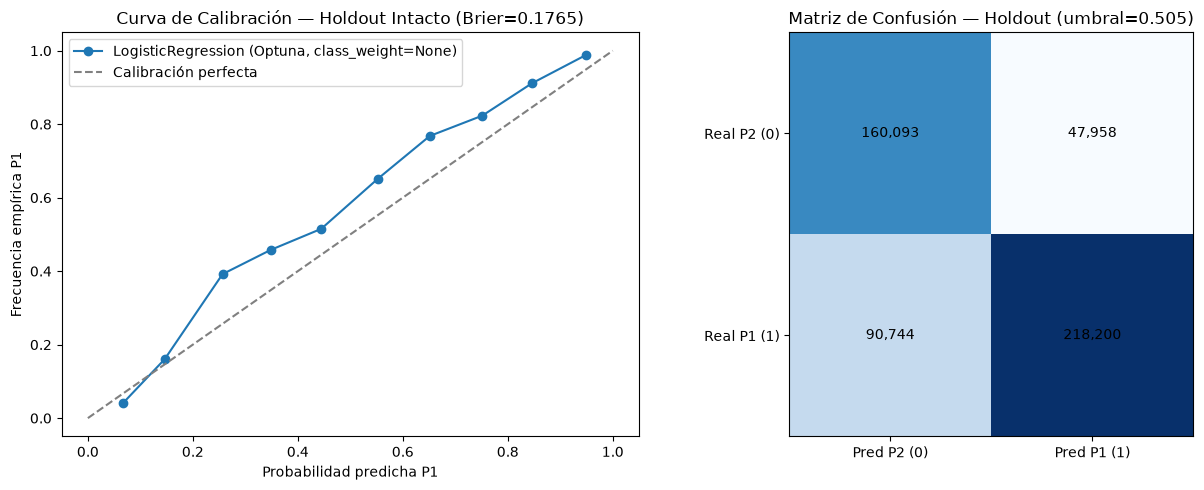

In [10]:
# Reentrenamiento final sobre TODO X_train
final_pipeline = clone(winner_pipe_unfitted)
t0 = time.perf_counter()
final_pipeline.fit(X_train, y_train)
fit_time_final = time.perf_counter() - t0

# Cargar y depurar el nuevo holdout intacto UNA SOLA VEZ al final
df_hold_raw = pd.read_parquet(HOLDOUT_DATA_PATH)
df_hold = canonicalize_match_ids(df_hold_raw)
del df_hold_raw
df_hold = df_hold.loc[
    ~((df_hold["frame"] < 0) | (df_hold["p1_stock"] == 0) | (df_hold["p2_stock"] == 0))
].reset_index(drop=True)

X_holdout = df_hold.drop(columns=[TARGET]).reset_index(drop=True)
y_holdout = (df_hold[TARGET] == 1).astype(int).reset_index(drop=True)
assert set(df_hold[ID_GROUP]).isdisjoint(set(groups_train) | set(groups_test)), "Holdout solapado con dev."


def evaluate_split(split_name: str, X_eval: pd.DataFrame, y_eval: pd.Series) -> tuple[dict, np.ndarray, np.ndarray]:
    proba = final_pipeline.predict_proba(X_eval)[:, 1]
    preds = (proba >= BEST_THRESHOLD).astype(int)
    heur = predict_domain_heuristic(X_eval)
    y_np = y_eval.to_numpy()
    summary = {
        "Conjunto": split_name,
        "Partidas": int(X_eval[ID_GROUP].nunique()),
        "Frames": int(len(X_eval)),
        "Model Acc": float(accuracy_score(y_np, preds)),
        "Heur Acc": float(accuracy_score(y_np, heur)),
        "Model F1": float(f1_score(y_np, preds, average="macro")),
        "Heur F1": float(f1_score(y_np, heur, average="macro")),
        "Model ROC AUC": float(roc_auc_score(y_np, proba)),
        "Model Brier": float(brier_score_loss(y_np, proba)),
    }
    return summary, proba, preds


test_summary, proba_test, pred_test = evaluate_split("Test (Dev 20%)", X_test, y_test)
hold_summary, proba_hold, pred_hold = evaluate_split("Holdout Intacto (00fd+00fe)", X_holdout, y_holdout)

eval_table = pd.DataFrame([test_summary, hold_summary])
display(eval_table)

# Desglose por Fase (Early / Mid / Late) en Test y Holdout
phase_rows = []
for sname, X_ev, y_ev, pr_ev in [
    ("Test", X_test, y_test.to_numpy(), pred_test),
    ("Holdout Intacto", X_holdout, y_holdout.to_numpy(), pred_hold),
]:
    phases = assign_phase(X_ev["frame"])
    heur_ev = predict_domain_heuristic(X_ev)
    for ph in ["Early (<5k)", "Mid (5k-12k)", "Late (>=12k)"]:
        m = phases == ph
        if m.any():
            phase_rows.append({
                "Conjunto": sname,
                "Fase": ph,
                "Frames": int(m.sum()),
                "Model Acc": float(accuracy_score(y_ev[m], pr_ev[m])),
                "Heur Acc": float(accuracy_score(y_ev[m], heur_ev[m])),
            })

print("\nDesglose por fase (Early / Mid / Late):")
display(pd.DataFrame(phase_rows))

# Desglose por match_id individual (Holdout Intacto)
hold_eval_df = pd.DataFrame({
    "match_id": X_holdout[ID_GROUP].values,
    "y_true": y_holdout.to_numpy(),
    "y_pred": pred_hold,
    "y_heur": predict_domain_heuristic(X_holdout),
    "stock_diff": (X_holdout["p1_stock"] - X_holdout["p2_stock"]).to_numpy(),
})
hold_eval_df["model_ok"] = (hold_eval_df["y_true"] == hold_eval_df["y_pred"]).astype(int)
hold_eval_df["heur_ok"] = (hold_eval_df["y_true"] == hold_eval_df["y_heur"]).astype(int)

per_match_hold = (
    hold_eval_df.groupby("match_id", as_index=False)
    .agg(
        frames=("y_true", "size"),
        outcome=("y_true", "first"),
        model_acc=("model_ok", "mean"),
        heur_acc=("heur_ok", "mean"),
    )
    .sort_values("model_acc", ascending=True)
)
print(f"\nResumen por match_id en Holdout Intacto ({len(per_match_hold)} partidas):")
print(per_match_hold[["model_acc", "heur_acc"]].describe().round(4))
display(per_match_hold.head(10))

# Desglose por stock_diff y análisis de desacuerdos (Test + Holdout)
print("\nDesglose por stock_diff en Holdout Intacto:")
by_stock_diff = (
    hold_eval_df.groupby("stock_diff", as_index=False)
    .agg(frames=("y_true", "size"), model_acc=("model_ok", "mean"), heur_acc=("heur_ok", "mean"))
)
display(by_stock_diff)

disagree = hold_eval_df[hold_eval_df["y_pred"] != hold_eval_df["y_heur"]]
print(
    f"\nDesacuerdos Modelo vs Heurística (Holdout): {len(disagree):,} / {len(hold_eval_df):,} frames "
    f"({len(disagree) / len(hold_eval_df):.2%}) | "
    f"En desacuerdos: Model Acc={disagree['model_ok'].mean():.4f} vs Heur Acc={disagree['heur_ok'].mean():.4f}"
)

# Curva de calibración y matriz de confusión en Holdout Intacto
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
prob_true, prob_pred = calibration_curve(y_holdout, proba_hold, n_bins=10, strategy="uniform")
axes[0].plot(prob_pred, prob_true, marker="o", label=f"{WINNER_NAME}")
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Calibración perfecta")
axes[0].set_title(f"Curva de Calibración — Holdout Intacto (Brier={hold_summary['Model Brier']:.4f})")
axes[0].set_xlabel("Probabilidad predicha P1")
axes[0].set_ylabel("Frecuencia empírica P1")
axes[0].legend()

cm_hold = confusion_matrix(y_holdout, pred_hold)
axes[1].imshow(cm_hold, cmap="Blues")
axes[1].set_title(f"Matriz de Confusión — Holdout (umbral={BEST_THRESHOLD:.3f})")
axes[1].set_xticks([0, 1], ["Pred P2 (0)", "Pred P1 (1)"])
axes[1].set_yticks([0, 1], ["Real P2 (0)", "Real P1 (1)"])
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, f"{cm_hold[i, j]:,}", ha="center", va="center", color="black")
plt.tight_layout()
plt.show()

## Sección 8 — Serialización de Modelo, Metadatos y Verificaciones Finales

In [11]:
# Serialización del modelo final y metadatos
model_path = MODELS_DIR / "final_model.joblib"
joblib.dump(final_pipeline, model_path)

model_metadata = {
    "winner_model": WINNER_NAME,
    "feature_config": BEST_FEATURE_KWARGS,
    "best_params": study_hgb.best_params if "HistGradientBoosting" in WINNER_NAME else study_lr.best_params,
    "oof_optimal_threshold": BEST_THRESHOLD,
    "cv_protocol": "StratifiedGroupKFold(n_splits=5)",
    "fit_time_seconds": fit_time_final,
    "test_metrics": test_summary,
    "holdout_metrics": hold_summary,
    "versions": {
        "python": platform.python_version(),
        "scikit_learn": sklearn.__version__,
        "optuna": optuna.__version__,
    },
}
meta_path = MODELS_DIR / "model_metadata.json"
meta_path.write_text(json.dumps(model_metadata, indent=2), encoding="utf-8")

# Aserciones finales de cierre
assert model_path.exists() and meta_path.exists()
assert "outcome" not in X_train.columns and "outcome" not in X_test.columns and "outcome" not in X_holdout.columns
assert set(groups_train).isdisjoint(set(groups_test))
assert set(df_hold[ID_GROUP]).isdisjoint(set(groups_train) | set(groups_test))
assert 0.35 <= BEST_THRESHOLD <= 0.65
assert test_summary["Model Acc"] > 0.50 and hold_summary["Model Acc"] > 0.70

print(f"Modelo serializado en : {model_path}")
print(f"Metadatos guardados en: {meta_path}")
print("Verificaciones finales de Fase 3: 100% PASSED")

Modelo serializado en : /mnt/Qui/@home/spinangoalamo/codes/Machine Learning/super_smash_bros_melee_victory_predictor/models/final_model.joblib
Metadatos guardados en: /mnt/Qui/@home/spinangoalamo/codes/Machine Learning/super_smash_bros_melee_victory_predictor/models/model_metadata.json
Verificaciones finales de Fase 3: 100% PASSED
